# MiniLLM: Shakespeare Text Generation
**MATH_X405 Project**

Implementation and experiments based on
[angelos-p/llm-from-scratch](https://github.com/angelos-p/llm-from-scratch/tree/63069f99af8ce9a6ab6e261000f4f9f1daaa1ee9).
The accompanying [report](https://github.com/Bubble0128/MiniLLM/blob/main/Report_English.md)
contains the methods, experiment discussion sections, and attention proof.

Select a GPU runtime and run the cells in order. `EXPERIMENT` selects the tutorial `baseline`, the `tiny`, `small` and `medium` size comparison, or the `final` model. The saved outputs were produced with `final`, reading the results trained on an RTX 5080 (`RUN_TRAINING = False`).


## 1. Setup
Auxiliary functions are maintained in separate Python modules. Google Drive stores
checkpoints and results across Colab sessions.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_DIR = Path("/content/MiniLLM_submission") if IN_COLAB else Path.cwd()
if not (PROJECT_DIR / "model.py").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Bubble0128/MiniLLM.git", str(PROJECT_DIR)], check=True)
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
if IN_COLAB:  # a local environment is expected to have requirements.txt installed
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

import torch
from train import get_device

DEVICE = get_device()
USE_DRIVE = True #@param {type:"boolean"}
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RUNS_ROOT = Path("/content/drive/MyDrive/MiniLLM/runs")
else:
    RUNS_ROOT = PROJECT_DIR / "runs"
RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))
print("Device:", DEVICE, "| PyTorch:", torch.__version__)
print("Results:", RUNS_ROOT)


Device: cuda | PyTorch: 2.11.0+cu128
Results: /home/chenrui/projects/MiniLLM/runs


## 2. Experimental configuration

| Experiment | Layers | Heads | Embedding dimension | Dropout | Purpose |
|---|---:|---:|---:|---:|---|
| baseline | 6 | 6 | 384 | 0 | Tutorial configuration |
| tiny | 2 | 2 | 128 | 0.1 | Lower capacity |
| small | 4 | 4 | 256 | 0.1 | Intermediate capacity |
| medium | 6 | 6 | 384 | 0.1 | Default size with regularization |
| final | 6 | 6 | 384 | 0.1 | Untied output projection, lower learning rate |

The size experiments use context length 256, batch size 64, at most 10,000 updates, AdamW,
100 warmup steps, cosine learning-rate decay (0.001 to 0.0001), weight decay
0.01, and gradient clipping at 1.0. Evaluation uses 20 fixed batches per split
every 100 updates. Stop after five consecutive evaluations without a strictly lower
validation CE. Generate with the best checkpoint. Actual steps and token budgets
may differ. The cosine schedule uses the 10,000-step horizon. All reported losses are CE. The historical baseline used dropout 0 and no early stopping.
`final` changes these to 5,000 updates, 150 warmup steps, cosine decay from 0.0003 to 0.00003,
weight decay 0.1 and no early stopping (report Sections 3.2 to 3.4).
Change `RUN_TAG` when changing parameters.


In [2]:
from dataclasses import asdict, replace
import json
from train import experiment_config

EXPERIMENT = "final" #@param ["baseline", "tiny", "small", "medium", "final"]
RUN_TAG = "5080_v1" #@param {type:"string"}
RESUME = True #@param {type:"boolean"}

model_config, train_config = experiment_config(EXPERIMENT)
# Apply any shared training changes consistently across compared experiments.
# train_config = replace(train_config, batch_size=32)

PROMPT = "To be, or not to be, that is the question:\n"  # Hamlet, Act 3, Scene 1
MAX_NEW_TOKENS = 800
TEMPERATURES = (0.6, 0.8, 1.0, 1.2)
TOP_K = 10
SEEDS = (42, 123, 2026)
SAMPLE_TAG = "hamlet_topk10_v1"  # Change this when modifying the prompt or sampling settings.

for label in (RUN_TAG, SAMPLE_TAG):
    if not label or any(c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-" for c in label):
        raise ValueError("Tags must contain only letters, digits, underscores or hyphens")
RUN_DIR = RUNS_ROOT / f"{EXPERIMENT}_{RUN_TAG}"
print(json.dumps({"model": asdict(model_config), "training": asdict(train_config)}, indent=2))


{
  "model": {
    "vocab_size": 65,
    "block_size": 256,
    "n_layer": 6,
    "n_head": 6,
    "n_embd": 384,
    "dropout": 0.1,
    "residual_scale": 1.0,
    "weight_tying": false
  },
  "training": {
    "max_steps": 5000,
    "batch_size": 64,
    "max_lr": 0.0003,
    "min_lr": 2.9999999999999997e-05,
    "warmup_steps": 150,
    "weight_decay": 0.1,
    "grad_clip": 1.0,
    "eval_interval": 100,
    "eval_batches": 20,
    "seed": 42,
    "eval_seed": 12345,
    "patience": 0,
    "optimizer_name": "adamw",
    "momentum": 0.9,
    "eval_batch_size": 64,
    "eval_block_size": 256,
    "tokenizer_type": "character",
    "micro_batch_size": null
  }
}


## 3. Data and model
The pinned Shakespeare corpus is encoded at character level and split contiguously
into 90% training and 10% validation data. Targets are inputs shifted by one character.
The model combines token and learned positional embeddings, pre-normalized causal
attention blocks, residual connections, a 4x-width GELU MLP, and an output head tied to the token embedding (untied in `final`).


In [3]:
from data import CharacterData, download_shakespeare
from model import GPT

DATA_PATH = download_shakespeare(PROJECT_DIR / "data/shakespeare.txt")
dataset = CharacterData(DATA_PATH)
model_config = replace(model_config, vocab_size=len(dataset.chars))
dataset.encode(PROMPT)
print("Vocabulary:", len(dataset.chars))
print("Training characters:", len(dataset.splits["train"]))
print("Validation characters:", len(dataset.splits["val"]))
print("Data SHA256:", dataset.sha256)
parameter_model = GPT(model_config)
print("Parameters:", sum(p.numel() for p in parameter_model.parameters()))
del parameter_model


Vocabulary: 65
Training characters: 1003854
Validation characters: 111540
Data SHA256: 86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed
Parameters: 10795776


## 4. Training
Training and validation losses are measured in evaluation mode on fixed sampled
windows. The lowest observed validation loss selects `best.pt`; `last.pt` stores
the optimizer and random states for resuming training.


In [4]:
from train import train

RUN_TRAINING = False #@param {type:"boolean"}
if RUN_TRAINING:
    summary = train(DATA_PATH, RUN_DIR, model_config, train_config, device=DEVICE,
                    resume=RESUME and (RUN_DIR / "last.pt").exists())
else:
    if not (RUN_DIR / "summary.json").exists():
        raise FileNotFoundError("Upload existing results or set RUN_TRAINING=True.")
    summary = json.loads((RUN_DIR / "summary.json").read_text())
print("Best validation loss:", summary["best_val_loss"])
print("Best checkpoint step:", summary["best_step"])


Best validation loss: 1.4753447353839875
Best checkpoint step: 4400


## 5. Loss curves
Loss is cross-entropy in nats per character. Validation data are used for model
selection, rather than as an independent test set.


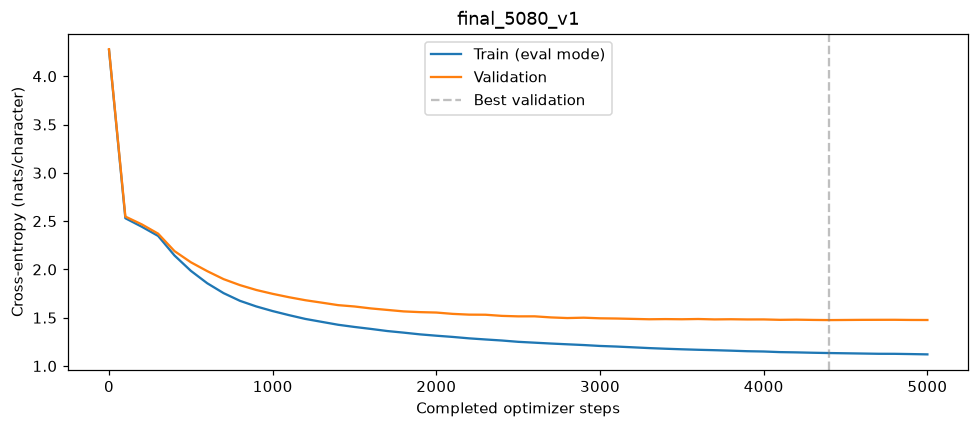

In [5]:
import matplotlib.pyplot as plt
from analysis import plot_history

figure = plot_history(RUN_DIR)
plt.show()
plt.close(figure)


## 6. Soliloquy continuation
Each sample continues the first line of Hamlet's soliloquy using the best checkpoint.
The prompt, generation length, seed list and top-k are fixed across models.
Temperature is varied independently of training; all samples are retained.


In [6]:
from generate import save_samples

samples = save_samples(
    RUN_DIR / "best.pt", RUN_DIR / f"samples_{SAMPLE_TAG}", device=DEVICE,
    prompt=PROMPT, temperatures=TEMPERATURES, top_k=TOP_K, seeds=SEEDS,
    max_new_tokens=MAX_NEW_TOKENS,
)
for sample in samples:
    print(f"\nTemperature: {sample['temperature']} | Seed: {sample['seed']}")
    print(sample["text"])



Temperature: 0.6 | Seed: 42
To be, or not to be, that is the question:
His lord and that the maid with a bastard of charge
And tears of a stranger of a woman's prignify,
And then it is a subject man.

First Lord:
No, the king and hours of his children but
That he hath been the seat of his course
To be move and his wisher blood.

First Senator:
He is may be so much so.

First Servingman:
He hath heard the world, to the house of York
The wrinkled-hearted of the death of the first
To be this thing story with the winged here,
And bear this manner in the house of heaven.

First Citizen:
Why, what she hath hath made me against the moon of them?

COMINIUS:
A gentleman to be to the feel of heaven,
And that the house of Northumberland,
So more than he hath been struck the company:
And therefore, there I think the father since often
And the entertain of the common and 

Temperature: 0.6 | Seed: 123
To be, or not to be, that is the question:
Therefore but the constant and then of the time
That t

## 7. Experiment comparison
The table includes completed experiments with the selected `RUN_TAG`. Compare loss,
training cost and generated text. The report connects observed spelling,
grammar, coherence and repetition to model and sampling choices.


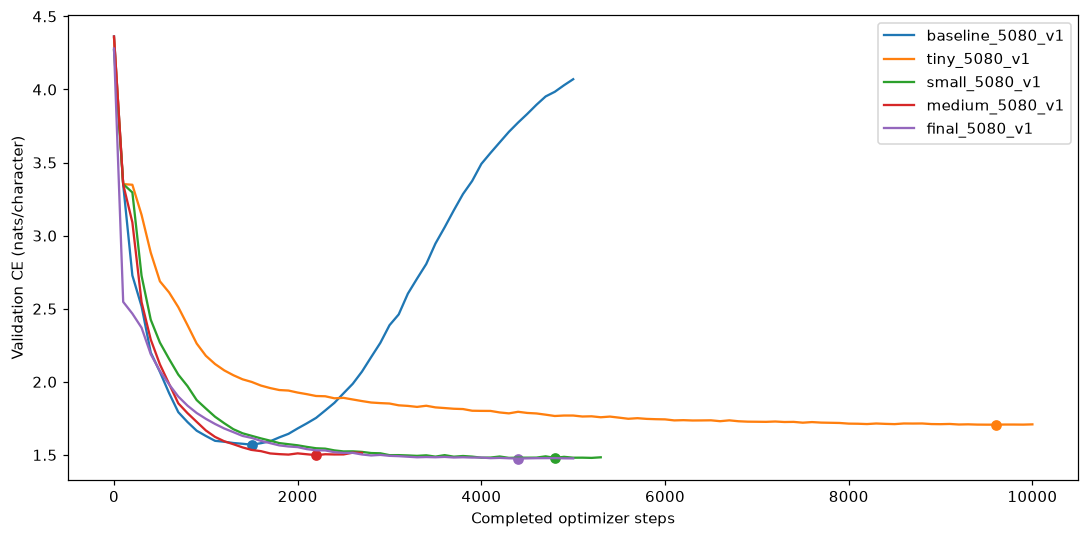

| Experiment | Parameters | Actual steps | Tokens | Best step | Best val loss | Final val loss | Minutes |
|---|---:|---:|---:|---:|---:|---:|---:|
| baseline_5080_v1 | 10,770,816 | 5000 | 81,920,000 | 1500 | 1.5701 | 4.0702 | 4.9 |
| tiny_5080_v1 | 437,888 | 10000 | 163,840,000 | 9600 | 1.7070 | 1.7091 | 1.1 |
| small_5080_v1 | 3,241,728 | 5300 | 86,835,200 | 4800 | 1.4793 | 1.4838 | 2.3 |
| medium_5080_v1 | 10,770,816 | 2700 | 44,236,800 | 2200 | 1.4986 | 1.5144 | 3.4 |
| final_5080_v1 | 10,795,776 | 5000 | 81,920,000 | 4400 | 1.4753 | 1.4762 | 6.4 |


In [7]:
from analysis import compare_runs, plot_validation_comparison
from IPython.display import Markdown, display

completed_runs = []
for name in ("baseline", "tiny", "small", "medium", "final"):
    path = RUNS_ROOT / f"{name}_{RUN_TAG}"
    summary_file = path / "summary.json"
    if summary_file.exists() and json.loads(summary_file.read_text())["complete"]:
        completed_runs.append(path)

if completed_runs:
    rows = compare_runs(completed_runs, RUNS_ROOT / f"comparison_{RUN_TAG}")
    display(plot_validation_comparison(completed_runs, RUNS_ROOT / f"comparison_{RUN_TAG}"))
    table = "| Experiment | Parameters | Actual steps | Tokens | Best step | Best val loss | Final val loss | Minutes |\n"
    table += "|---|---:|---:|---:|---:|---:|---:|---:|\n"
    for row in rows:
        table += (f"| {row['run']} | {row['parameters']:,} | {row['actual_steps']} | {row['tokens_seen']:,} | {row['best_step']} | "
                  f"{row['best_val_loss']:.4f} | {row['last_val_loss']:.4f} | "
                  f"{row['elapsed_minutes']:.1f} |\n")
    display(Markdown(table))
else:
    print("No completed experiments available.")


## 8. Submission files
The archive contains Python modules, the English source notebook, the English report,
and results from the completed experiments above. Download the executed notebook from
Colab separately to retain its displayed outputs. Model checkpoints remain in the
results directory.


In [8]:
from zipfile import ZipFile, ZIP_DEFLATED

DOWNLOAD_ARCHIVE = False #@param {type:"boolean"}
archive_path = RUNS_ROOT / f"MiniLLM_{RUN_TAG}.zip"
with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
    for name in ("model.py", "data.py", "train.py", "generate.py", "analysis.py",
                 "word_data.py", "sampling_comparison.py",
                 "requirements.txt", "MiniLLM_Submission.ipynb"):
        archive.write(PROJECT_DIR / name, f"code/{name}")
    archive.write(PROJECT_DIR / "Report_English.md", "report/Report_English.md")
    for run_dir in completed_runs:
        for path in run_dir.rglob("*"):
            if path.is_file() and path.suffix not in (".pt", ".tmp"):
                archive.write(path, f"results/{run_dir.name}/{path.relative_to(run_dir)}")
    comparison = RUNS_ROOT / f"comparison_{RUN_TAG}" / "comparison.csv"
    if completed_runs and comparison.exists():
        archive.write(comparison, "results/comparison.csv")
print("Archive:", archive_path)
if IN_COLAB and DOWNLOAD_ARCHIVE:
    from google.colab import files
    files.download(str(archive_path))


Archive: /home/chenrui/projects/MiniLLM/runs/MiniLLM_5080_v1.zip
